# Learning notebooks with Earthquake API

In this notebook we will:

- Make a request to the USGS API
- Interpret the result as a .csv
- Do some excel-style stats
- Make a graph

In [1]:
print("Hello World!")

Hello World!


In [ ]:
%pip install requests

import requests
import matplotlib.pyplot as plt



  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached charset_normalizer-3.5.2-cp313-cp313-macosx_10_13_universal2.whl.metadata (46 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached charset_normalizer-3.5.2-cp313-cp313-macosx_10_13_universal2.whl (366 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
Using cached urllib3-2.8.0-py3-none-any.whl (135 kB)
Using cached certifi-2026.7.22-py3-none-any.whl (136 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [requests]

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


In [6]:
base_url = "https://earthquake.usgs.gov/fdsnws/event/1/query"
full_url = base_url + "?format=csv"
print(full_url)

https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv


In [10]:
response = requests.get(full_url)
response.text.splitlines()[0:10]

['time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource',
 '2026-10-13T18:28:09.450Z,35.779666900635,-121.46183013916,-0.31999999284744,2.57,md,54,194,0.1694,0.25,nc,nc75448936,2026-10-13T18:34:43.950Z,"28 km SSE of Lopez Point, CA",earthquake,0.79,3.00999999,0.15,44,automatic,nc,nc',
 '2026-10-13T18:27:42.080Z,32.943833333333,-116.655,10.63,0.88,ml,9,262,0.06527,0.08,ci,ci41347151,2026-10-13T18:31:00.172Z,"14 km ESE of San Diego Country Estates, CA",earthquake,1.28,0.57,0.29901695691148,9,automatic,ci,ci',
 '2026-10-13T18:12:52.190Z,36.022833333333,-117.77883333333,1.35,0.87,ml,18,46,0.01126,0.16,ci,ci41347135,2026-10-13T18:16:23.738Z,"15 km NE of Little Lake, CA",earthquake,0.21,0.23,0.31587015158352,14,automatic,ci,ci',
 '2026-10-13T18:00:32.918Z,62.937,-151.247,107.8,2.4,ml,67,74,0.5,0.7,ak,aka2026uhugxh,2026-10-13T18:04:10.657Z,"54 km NNW of Petersville, Alaska",earthquake,2.6

## Let's reproduce from excel functions!

In [28]:
#how many earthquakes?
records = response.text.splitlines()[1:]
print(f"Number of earthquakes: {len(records) - 1}")  # Subtract 1 for the header row



Number of earthquakes: 10177


In [34]:
#highest magnitude in the dataset

magnitudes = []

#grab a single record
for r in records:
   magnitudes.append(float(r.split(",")[4]))
max(magnitudes)

7.7

# Let's visualize

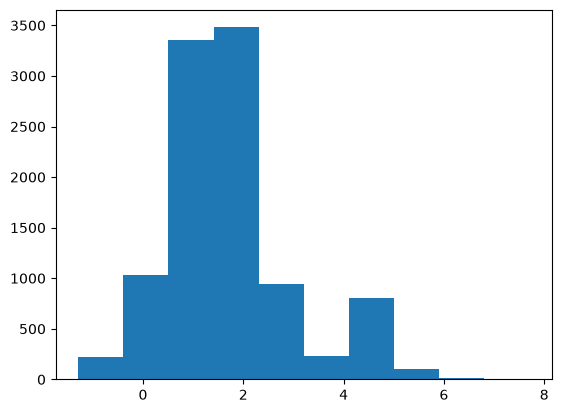

In [35]:
plt.hist(magnitudes)
plt.show()